# Activity: Should We Trust the Alarm? — FreshKart Cold-Chain Case

**Unit 4 · AI-Assisted Visualization · AI-Assisted Pattern and Anomaly Visualization**
Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

---

## The case

FreshKart's dark stores keep frozen food in **8 freezers** (one per store in Bengaluru, Pune and Hyderabad). Each freezer reports its temperature every hour. Last month FreshKart bought **ColdSense**, an AI service that scores every reading for "anomaly" and raises an alert when the score is **≥ 0.5**.

Cold-chain lead **Ravi** has six weeks of readings, the ColdSense scores, and the **maintenance log** (what technicians actually found). His technicians are tired of being sent out at night. He asks:

> *"Is ColdSense's alert feed trustworthy? Which alerts should my team chase, and what is it missing?"*

**You are the analyst.** Use the data and the visualizations to verify, correct or reject what the vendor claims.

**Ground rules (from the lecture):** an AI score is a *derived attribute*: look at it, don't only threshold it · flags are **candidates, not conclusions** · report precision and recall, not accuracy · scale emphasis to confidence.

**How to work:** run the notebook top to bottom. Complete every cell marked `# TODO` (replace `None` with your code or answer) and write in the cells marked **✏️ Your answer**. Cells that depend on your TODO will tell you if something is still missing.

### The data: `freshkart_coldchain.csv` (synthetic)

| Column | Meaning |
|---|---|
| `timestamp` | hour of the reading (1 Aug – 11 Sep 2026) |
| `city`, `store_id`, `freezer_id` | where the freezer is |
| `temp_c` | freezer temperature (°C); normal is about −18 °C |
| `door_opens` | number of door openings in that hour (busy by day, quiet at night) |
| `compressor_kw` | compressor power draw (kW) |
| `ai_score`, `ai_flag` | ColdSense anomaly score (0–1) and alert (1 if score ≥ 0.5) |
| `confirmed_fault`, `fault_type` | from the maintenance log: 1 if technicians confirmed a real fault in that hour, and what it was |

**Domain note from the maintenance team:** every freezer runs an automatic **defrost cycle from 02:00 to 04:00** each night. The heater warms the coil, so the temperature rises for those two hours. That is normal.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.spines.top": False, "axes.spines.right": False})
GREY, ACCENT, BLUE = "#bdbdbd", "#d95f02", "#4c78a8"

def ready(*vals):
    """Helper: tells you if a TODO above is still unanswered."""
    ok = all(v is not None for v in vals)
    if not ok:
        print("⚠ Complete the TODO cell(s) above first, then re-run this cell.")
    return ok

df = pd.read_csv("freshkart_coldchain.csv", parse_dates=["timestamp"])
df["hour"] = df["timestamp"].dt.hour
df.head()

,timestamp,city,store_id,freezer_id,temp_c,door_opens,compressor_kw,ai_score,ai_flag,confirmed_fault,fault_type,hour
0,2026-08-01,Bengaluru,B1,FZ-B1,-18.1,0,1.29,0.000,0,0,NaN,0
1,2026-08-01,Bengaluru,B2,FZ-B2,-18.7,0,1.16,0.000,0,0,NaN,0
2,2026-08-01,Bengaluru,B3,FZ-B3,-17.7,0,1.21,0.000,0,0,NaN,0
3,2026-08-01,Hyderabad,H1,FZ-H1,-17.8,0,1.30,0.037,0,0,NaN,0
4,2026-08-01,Hyderabad,H2,FZ-H2,-18.2,0,1.32,0.035,0,0,NaN,0


## ColdSense's monthly report (to be validated)

| # | Vendor statement |
|---|---|
| 1 | "ColdSense is **97.9% accurate**, so its alerts can be trusted." |
| 2 | "**Most faults happen around 2 am.** We recommend a night technician." |
| 3 | "**All 10 compressor trips** in the period were caught." |
| 4 | "Freezer **FZ-H2 ran without a single fault** in August." |
| 5 | "A reading of **−14 °C is abnormal** for any freezer, at any time." |
| 6 | "An alert with a score of **0.92 means a 92% chance** of a real fault." |
| 7 | "The **default threshold of 0.5** is the best setting for FreshKart." |
| 8 | "A new FZ-B1 reading of **−15.9 °C at 14:00** is **15 standard errors** above normal: a definite fault." |

---
## Part 1 · Data abstraction: items, attributes and derived attributes

Munzner: before choosing a view, ask what the **items** and **attributes** are. The AI does not change the items; it **derives** new attributes.

In [2]:
derived_cols = ["ai_score", "ai_flag"]
n_alerts = int((df.ai_flag == 1).sum())
fault_rate_pct = round(df.confirmed_fault.mean() * 100, 2)

if ready(derived_cols, n_alerts, fault_rate_pct):
    print(f"derived: {derived_cols} | alerts: {n_alerts} | faults: {df.confirmed_fault.sum()} of {len(df)} rows ({fault_rate_pct}%)")
    display(df[df.confirmed_fault == 1].groupby("fault_type").size().rename("fault hours"))

derived: ['ai_score', 'ai_flag'] | alerts: 159 | faults: 46 of 8064 rows (0.57%)


fault_type
compressor trip         10
defrost heater stuck    11
sensor frozen           25
Name: fault hours, dtype: int64

**✏️ Your answer (Part 1):** `ai_score` is quantitative and `ai_flag` is binary. Which **visual channel** suits each, and what information does the flag throw away that the score keeps?

*Your answer:*

`ai_score` is **quantitative**, so it suits a magnitude channel: position (for example, a score line or strip under the temperature trace), or an ordered colour luminance or saturation ramp, or size. `ai_flag` is **binary/categorical**, so it suits an identity channel: a distinct hue, mark shape, or presence/absence of a marker. The flag throws away **the magnitude and so the confidence**: a 0.51 and a 0.99 look identical. It also hides near-misses just below 0.5 (for example, the stuck-heater faults scoring about 0.37–0.39) and makes it impossible to choose a different threshold or rank alerts by priority.

---
## Part 2 · Distributions: bin width and the score distribution

### 2a · Temperature histogram

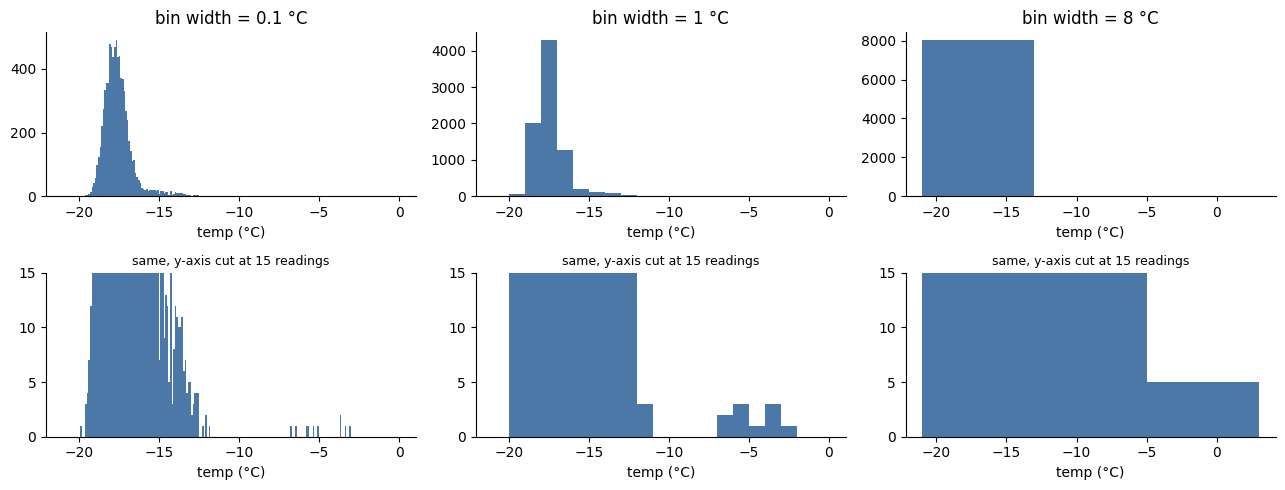

readings warmer than -8 °C: 10 | visible as a separate group at bin widths [0.1, 1]


In [3]:
fig, axes = plt.subplots(2, 3, figsize=(13, 5))
for col, w in enumerate([0.1, 1, 8]):
    for row, top in enumerate([None, 15]):
        ax = axes[row, col]
        ax.hist(df["temp_c"], bins=np.arange(-21, 0 + w, w), color=BLUE)
        if top: ax.set_ylim(0, top); ax.set_title(f"same, y-axis cut at {top} readings", fontsize=9)
        else: ax.set_title(f"bin width = {w} °C")
        ax.set_xlabel("temp (°C)")
plt.tight_layout(); plt.show()

warm_tail_visible_bins = [0.1, 1]
n_warm_readings = int((df["temp_c"] > -8).sum())
print(f"readings warmer than -8 °C: {n_warm_readings} | visible as a separate group at bin widths {warm_tail_visible_bins}")

### 2b · Look at the AI scores before trusting the cut-off
Wilke: compare groups with overlapping densities, not stacked histograms.

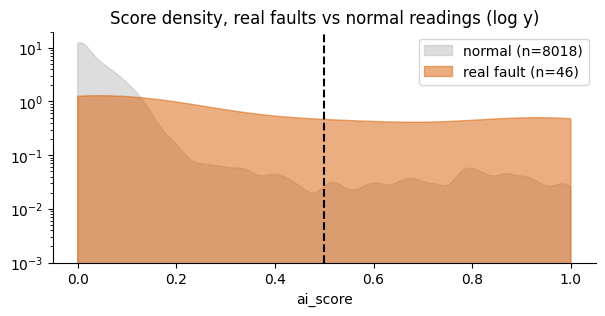

In [4]:
xs = np.linspace(0, 1, 300)
fig, ax = plt.subplots(figsize=(7, 3))
for lab, col in [(0, GREY), (1, ACCENT)]:
    s = df.loc[df.confirmed_fault == lab, "ai_score"]
    ax.fill_between(xs, stats.gaussian_kde(s)(xs), color=col, alpha=.5, label=f"{'real fault' if lab else 'normal'} (n={len(s)})")
ax.axvline(0.5, color="k", ls="--"); ax.set_yscale("log"); ax.set_ylim(1e-3, 20)
ax.set_xlabel("ai_score"); ax.legend(); ax.set_title("Score density, real faults vs normal readings (log y)")
plt.show()

scores_separate_faults = False   # the two densities overlap across 0.5; many faults score near 0, many normal readings score high

**✏️ Your answer (Part 2):** Why is a histogram "a parameterised algorithm", and what would you tell a colleague who says *"the 8 °C histogram shows no anomalies"*?

*Your answer:*

A histogram is not a neutral picture of the data. It is the output of an algorithm whose parameters (bin width, bin origin, axis range, y-limits) change what you see. Here, with 0.1 °C or 1 °C bins and the y-axis cut, the **10 readings warmer than −8 °C** (the compressor trips) appear as a separate warm group. With 8 °C bins they are merged into wide bins and hidden under the tall main peak. To the colleague: *"No anomalies at 8 °C bins means the bins are too wide, not that the data is clean. There are 10 readings above −8 °C. Try finer bins, cut or log the y-axis, or plot the individual points (rug or strip) before concluding there are no anomalies."*

---
## Part 3 · Outlier rules on a short window (vendor statement 3)

Ten consecutive readings from **FZ-P1**, 12 Aug 06:00–15:00. One of them is a compressor trip.

In [5]:
window = df[(df.freezer_id == "FZ-P1") & (df.timestamp >= "2026-08-12 06:00") & (df.timestamp < "2026-08-12 16:00")]
v = window["temp_c"].values
print(window[["timestamp", "temp_c", "fault_type"]].to_string(index=False))

z_max = np.max(np.abs((v - v.mean()) / np.std(v, ddof=1)))
q1, q3 = np.percentile(v, [25, 75])
upper_fence = q3 + 1.5 * (q3 - q1)

if ready(z_max, upper_fence):
    print(f"largest |z| = {z_max:.2f} -> flagged by |z| > 3? {z_max > 3}")
    print(f"upper IQR fence = {upper_fence:.2f} °C -> trip flagged by IQR rule? {v.max() > upper_fence}")
    print(f"largest |z| possible with n = {len(v)}: {(len(v) - 1) / np.sqrt(len(v)):.2f}")

          timestamp  temp_c      fault_type
2026-08-12 06:00:00   -17.5             NaN
2026-08-12 07:00:00   -18.2             NaN
2026-08-12 08:00:00   -17.4             NaN
2026-08-12 09:00:00   -17.7             NaN
2026-08-12 10:00:00   -16.6             NaN
2026-08-12 11:00:00    -3.6 compressor trip
2026-08-12 12:00:00   -17.0             NaN
2026-08-12 13:00:00   -16.8             NaN
2026-08-12 14:00:00   -17.7             NaN
2026-08-12 15:00:00   -17.7             NaN
largest |z| = 2.83 -> flagged by |z| > 3? False
upper IQR fence = -15.58 °C -> trip flagged by IQR rule? True
largest |z| possible with n = 10: 2.85


**✏️ Your answer (Part 3):** Explain in two sentences why the z-score rule missed the trip here (use the word *masking*) and why the IQR rule did not.

*Your answer:*

With only 10 readings, the trip (−3.6 °C) is itself part of the mean and SD. It drags the mean up and **inflates the SD**, so it hides itself. This is **masking**, and its |z| is only 2.83: with n = 10 the largest |z| possible is (n−1)/√n = 2.85, so a "|z| > 3" rule *cannot* fire on such a short window. The IQR rule uses the quartiles, which the single extreme value barely affects, so the upper fence stays at −15.6 °C and the −3.6 °C trip is far above it and correctly flagged.

---
## Part 4 · How good is ColdSense? (vendor statement 1)

In [6]:
flag = df.ai_flag == 1
real = df.confirmed_fault == 1

TP = int((flag & real).sum())
FP = int((flag & ~real).sum())
FN = int((~flag & real).sum())
TN = int((~flag & ~real).sum())

if ready(TP, FP, FN, TN):
    display(pd.DataFrame([[TP, FN], [FP, TN]], index=["real fault", "normal"], columns=["alert", "no alert"]))

,alert,no alert
real fault,16,30
normal,143,7875


In [7]:
precision = TP / (TP + FP)
recall = TP / (TP + FN)
f1 = 2 * precision * recall / (precision + recall)
accuracy = (TP + TN) / (TP + FP + FN + TN)
flag_nothing_accuracy = (FN + TN) / (TP + FP + FN + TN)   # = share of normal rows

if ready(precision, recall, f1, accuracy, flag_nothing_accuracy):
    print(f"precision = {precision:.2f} | recall = {recall:.2f} | F1 = {f1:.2f} | accuracy = {accuracy:.1%} | never-alert accuracy = {flag_nothing_accuracy:.1%}")

precision = 0.10 | recall = 0.35 | F1 = 0.16 | accuracy = 97.9% | never-alert accuracy = 98.0%


**✏️ Your answer (Part 4):** Rewrite vendor statement 1 so it is honest. Use precision and recall, and say in plain words what they mean for Ravi's technicians (how many call-outs are wasted, how many faults are missed).

*Your answer:*

*"ColdSense scores 97.9% accuracy, but that is slightly **worse** than a detector that never raises an alert (98.0%), because only 0.57% of readings are real faults. Measured properly, its **precision is 0.10**: of 159 alerts, only 16 were real faults, so **about 9 in 10 call-outs (143) are wasted**. Its **recall is 0.35**: of 46 confirmed fault hours, **30 were missed (65%)**, including every frozen-sensor fault. F1 = 0.16. Treat its alerts as candidates to review, not instructions to dispatch."*

---
## Part 5 · Thresholds and costs (vendor statement 7)

A missed fault can spoil a freezer of stock (cost ≈ **40** units); a false call-out costs **1** unit of technician time.

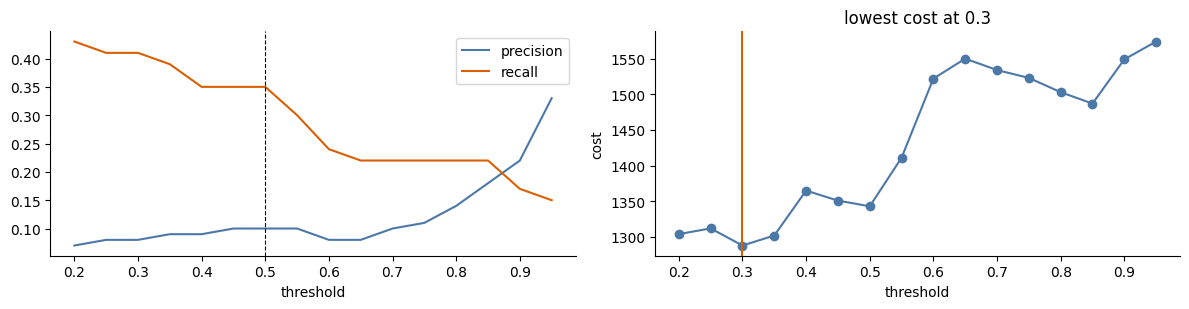

,threshold,TP,FP,FN,precision,recall,cost
0,0.20,20,264,26,0.07,0.43,1304
1,0.25,19,232,27,0.08,0.41,1312
2,0.30,19,208,27,0.08,0.41,1288
3,0.35,18,182,28,0.09,0.39,1302
4,0.40,16,165,30,0.09,0.35,1365
5,0.45,16,151,30,0.10,0.35,1351
6,0.50,16,143,30,0.10,0.35,1343
7,0.55,14,131,32,0.10,0.30,1411
8,0.60,11,122,35,0.08,0.24,1522
9,0.65,10,110,36,0.08,0.22,1550


In [8]:
grid = np.round(np.arange(0.20, 0.96, 0.05), 2)
sweep = pd.DataFrame({"threshold": grid})
sweep["TP"] = [((df.ai_score >= g) & real).sum() for g in grid]
sweep["FP"] = [((df.ai_score >= g) & ~real).sum() for g in grid]
sweep["FN"] = real.sum() - sweep["TP"]
sweep["precision"] = (sweep.TP / (sweep.TP + sweep.FP)).round(2)
sweep["recall"] = (sweep.TP / real.sum()).round(2)

sweep["cost"] = 40 * sweep["FN"] + 1 * sweep["FP"]
best_threshold = sweep.loc[sweep["cost"].astype(float).idxmin(), "threshold"]

if ready(best_threshold) and sweep["cost"].notna().all():
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
    ax[0].plot(sweep.threshold, sweep.precision, color=BLUE, label="precision"); ax[0].plot(sweep.threshold, sweep.recall, color=ACCENT, label="recall")
    ax[0].axvline(0.5, color="k", ls="--", lw=.8); ax[0].legend(); ax[0].set_xlabel("threshold")
    ax[1].plot(sweep.threshold, sweep.cost.astype(float), color=BLUE, marker="o"); ax[1].axvline(best_threshold, color=ACCENT)
    ax[1].set_xlabel("threshold"); ax[1].set_ylabel("cost"); ax[1].set_title(f"lowest cost at {best_threshold}")
    plt.tight_layout(); plt.show()
    display(sweep)

**✏️ Your answer (Part 5):** Even at the best threshold, recall stays low. Why can no threshold fix this detector? (Hint: look at *which* faults are never scored high.)

*Your answer:*

Because recall is limited by **which kinds of fault the score can see**, not by where the line is drawn. All 25 **sensor-frozen** fault hours score below 0.1 (mean 0.02): the reading looks like a perfectly normal −18 °C. It is only abnormal as a *run* of identical values (a collective anomaly), and ColdSense scores one reading at a time. Several stuck-heater faults also score only 0.19–0.39 because −15 °C is not extreme in absolute terms. Lowering the threshold far enough to reach them floods the team with 02:00 defrost false alarms, which score just as high. Even the cheapest threshold (0.30, cost 1288 against 1343 at 0.50) reaches recall of only 0.41. Fixing this needs new features (context by hour, a rolling-variance or "stuck value" check), not a new threshold.

---
## Part 6 · Where do the errors come from?

### 6a · When do the false alarms happen? (vendor statement 2)

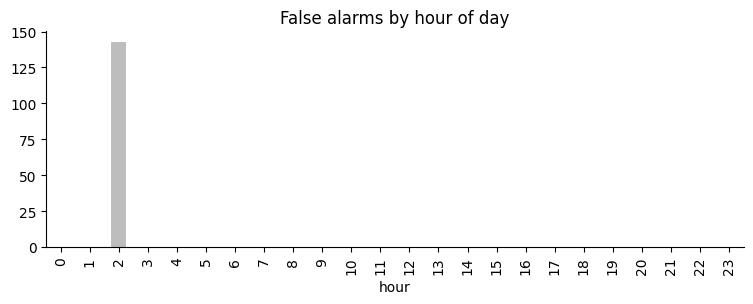

100% of false alarms happen at 2:00


In [9]:
fp_rows = df[flag & ~real]
fp_rows.groupby("hour").size().reindex(range(24), fill_value=0).plot.bar(color=GREY, title="False alarms by hour of day", figsize=(9, 2.8))
plt.show()

fp_peak_hour = int(fp_rows["hour"].value_counts().idxmax())
fp_share_at_peak = (fp_rows["hour"] == fp_peak_hour).mean()

if ready(fp_peak_hour, fp_share_at_peak):
    print(f"{fp_share_at_peak:.0%} of false alarms happen at {fp_peak_hour}:00")

### 6b · Which faults does ColdSense miss?

In [10]:
caught = df[real].groupby("fault_type")["ai_flag"].agg(caught="sum", fault_hours="size")
caught["recall"] = (caught.caught / caught.fault_hours).round(2)
display(caught)

never_caught_type = caught.index[caught["caught"] == 0][0]   # 'sensor frozen'
anomaly_kind = 'collective'
print(never_caught_type, '->', anomaly_kind)

,caught,fault_hours,recall
fault_type,,,
compressor trip,10,10,1.00
defrost heater stuck,6,11,0.55
sensor frozen,0,25,0.00


sensor frozen -> collective


### 6c · Contextual anomalies: compare each reading with its own hour

A **context-aware** baseline compares each reading with the same freezer at the same hour of day (median and MAD over the six weeks).

In [11]:
grp = df.groupby(["freezer_id", "hour"])["temp_c"]
df["hour_median"] = grp.transform("median")
df["hour_mad"] = grp.transform(lambda s: 1.4826 * stats.median_abs_deviation(s))

df["z_context"] = (df["temp_c"] - df["hour_median"]) / df["hour_mad"]

if ready(*df["z_context"].head(1)):
    ctx_flag = df["z_context"].astype(float) > 4
    found = df[real & ctx_flag & ~flag]
    print(f"Real faults the context baseline catches but ColdSense missed: {len(found)}")
    display(found[["timestamp", "freezer_id", "temp_c", "hour_median", "z_context", "ai_score", "fault_type"]])
    print(f"False alarms at 02:00 under the context baseline: {(ctx_flag & ~real & (df.hour == 2)).sum()} (ColdSense: {(flag & ~real & (df.hour == 2)).sum()})")

Real faults the context baseline catches but ColdSense missed: 3


,timestamp,freezer_id,temp_c,hour_median,z_context,ai_score,fault_type
1279,2026-08-07 15:00:00,FZ-P2,-14.6,-17.50,4.890058,0.369,defrost heater stuck
4731,2026-08-25 15:00:00,FZ-H1,-14.8,-17.50,6.070417,0.388,defrost heater stuck
6273,2026-09-02 16:00:00,FZ-B2,-15.2,-17.35,4.143300,0.189,defrost heater stuck


False alarms at 02:00 under the context baseline: 0 (ColdSense: 143)


### 6d · Collective anomalies: a run of readings that is abnormal together

                           min                 max  count
freezer_id                                               
FZ-H2      2026-08-20 14:00:00 2026-08-20 22:00:00      9
FZ-P1      2026-09-06 12:00:00 2026-09-06 17:00:00      6


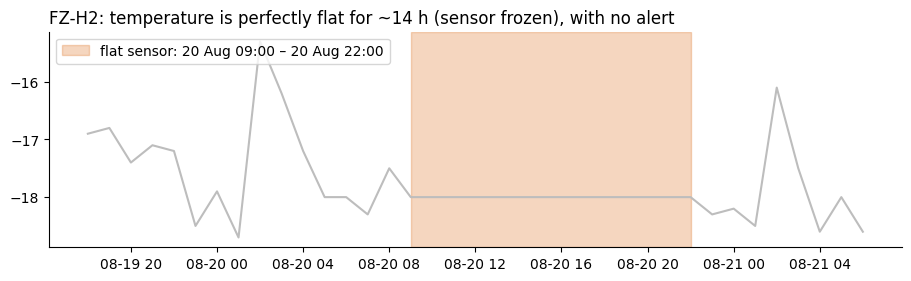

In [12]:
df = df.sort_values(["freezer_id", "timestamp"])
df["roll_sd_6h"] = df.groupby("freezer_id")["temp_c"].transform(lambda s: s.rolling(6).std())

flat = df[df["roll_sd_6h"] < 0.01]

if ready(flat):
    print(flat.groupby("freezer_id")["timestamp"].agg(["min", "max", "count"]))
    h2 = df[(df.freezer_id == "FZ-H2") & (df.timestamp.between("2026-08-19 18:00", "2026-08-21 06:00"))]
    fig, ax = plt.subplots(figsize=(11, 2.8))
    ax.plot(h2.timestamp, h2.temp_c, color=GREY)
    # highlight the whole flat span: the rolling window is 6 h, so the run starts 5 h before the first flagged row
    h2_flat = flat[flat.freezer_id == "FZ-H2"]["timestamp"]
    start, end = h2_flat.min() - pd.Timedelta(hours=5), h2_flat.max()
    ax.axvspan(start, end, color=ACCENT, alpha=.25, label=f"flat sensor: {start:%d %b %H:%M} – {end:%d %b %H:%M}")
    ax.legend(loc="upper left")

    ax.set_title("FZ-H2: temperature is perfectly flat for ~14 h (sensor frozen), with no alert", loc="left"); plt.show()
df = df.sort_values(["timestamp", "store_id"])

**✏️ Your answer (Part 6):**
(a) Rewrite vendor statement 2. What really happens at 2 am, and what would happen if FreshKart hired a night technician based on the vendor's report?
(b) Is vendor statement 5 true? Use the words *contextual anomaly* and say what a chart must show for a viewer to judge such an alert.
(c) What is wrong with vendor statement 4, and why can a detector that scores readings one at a time never catch this kind of fault?

*Your answer:*

**(a)** *"ColdSense raises its alerts at around 2 am, but none of them are faults. **100% of the 143 false alarms occur at 02:00**, during the scheduled defrost cycle when the temperature normally rises. Real faults (compressor trips, stuck heaters, frozen sensors) all occurred between 07:00 and 22:00, mostly in the afternoon."* A night technician hired on the vendor's advice would be sent out about 3–4 times a night to healthy freezers in defrost, at extra cost and with growing alert fatigue. Meanwhile the real daytime faults would still go uncovered and 30 would still be missed.

**(b)** **False.** −14 °C is a **contextual anomaly**: it is normal at 02:00 during defrost (the 02:00 median is −14.7 °C), but abnormal at, say, 15:00, when this freezer normally sits at −17.5 °C. That is how the stuck-heater faults appear, and the context baseline caught 3 that ColdSense missed while giving 0 false alarms at 02:00 (ColdSense gave 143). A chart for judging such an alert must show the **context**: the reading against the same freezer's normal band for that hour of day (for example, a median ± MAD band by hour), with the defrost window marked, rather than one fixed threshold line.

**(c)** It is wrong: the maintenance log records **14 fault hours on 20 Aug (09:00–22:00) where the FZ-H2 sensor was frozen**. The trace is perfectly flat (6-h rolling SD ≈ 0) and ColdSense gave no alert. This is a **collective anomaly**: each reading on its own is a perfectly normal-looking value, and only the *sequence* (zero variation where normal readings fluctuate) is abnormal. A detector that scores readings one at a time has no memory of neighbouring readings, so it can never see "the same value for 14 hours". It needs windowed features such as rolling SD, run length of identical values, or correlation with door openings and compressor power.

---
## Part 7 · Highlighting, saliency and frequency framing (vendor statement 6)

### 7a · Emphasis scaled to confidence
The vendor's dashboard paints every alert bright red. Implement the lecture's checklist: **≥ 0.90 strong**, **0.70–0.90 moderate**, **0.50–0.70 subtle outline**, **below 0.50 no emphasis** (the data stays visible).

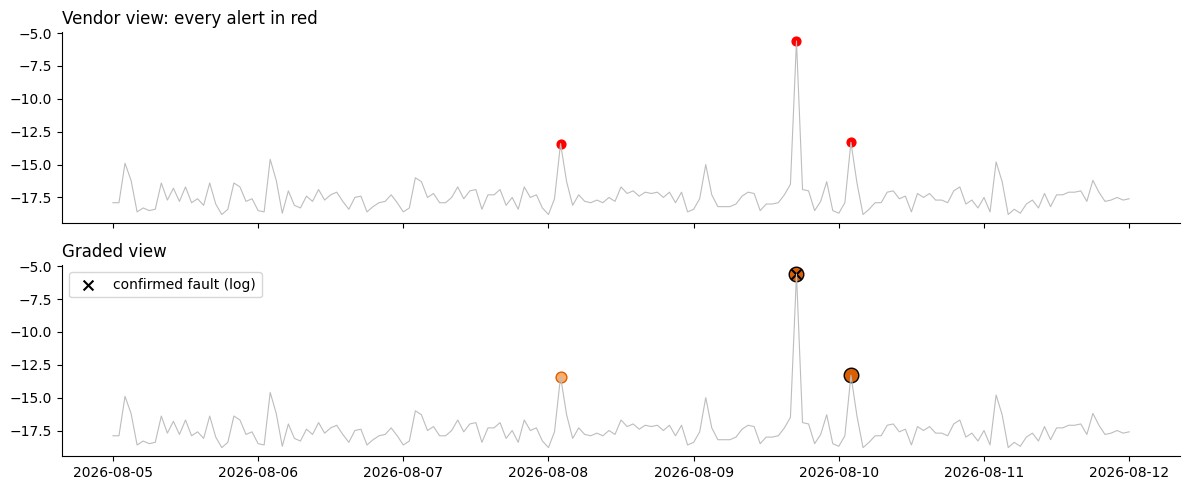

In [13]:
def emphasis(score):
    """Return (colour, marker size, edge colour) for one reading."""
    if score >= 0.90:
        return (ACCENT, 110, "black")      # strong: filled accent, large, dark edge
    if score >= 0.70:
        return ("#fdae6b", 60, ACCENT)     # moderate: lighter fill, medium size
    if score >= 0.50:
        return ("none", 45, ACCENT)        # subtle: outline only
    return (GREY, 0, "none")               # below 0.5: no emphasis, the line stays visible

week = df[(df.freezer_id == "FZ-B2") & (df.timestamp.between("2026-08-05", "2026-08-12"))]
if ready(emphasis(0.95)):
    fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
    ax[0].plot(week.timestamp, week.temp_c, color=GREY, lw=.8)
    a = week[week.ai_flag == 1]; ax[0].scatter(a.timestamp, a.temp_c, color="red", s=40); ax[0].set_title("Vendor view: every alert in red", loc="left")
    ax[1].plot(week.timestamp, week.temp_c, color=GREY, lw=.8)
    for _, r in week[week.ai_score >= 0.5].iterrows():
        col, size, edge = emphasis(r.ai_score)
        ax[1].scatter(r.timestamp, r.temp_c, color=col, s=size, edgecolors=edge)
    f_ = week[week.confirmed_fault == 1]; ax[1].scatter(f_.timestamp, f_.temp_c, marker="x", color="k", s=50, label="confirmed fault (log)")
    ax[1].legend(loc="upper left"); ax[1].set_title("Graded view", loc="left"); plt.tight_layout(); plt.show()

### 7b · "A score of 0.92 means 92%"? Count it.
Wilke: people read probabilities better as **frequencies**. Of all alerts in a score band, how many were real?

score >= 0.9: 8 real of 37 | score 0.5-0.7: 6 real of 55


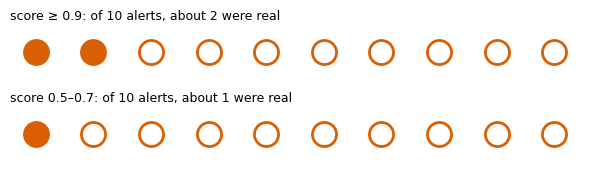

In [14]:
band_hi = df[df.ai_score >= 0.9]
band_lo = df[(df.ai_score >= 0.5) & (df.ai_score < 0.7)]

real_per_10_hi = int(round(band_hi.confirmed_fault.mean() * 10))
print(f"score >= 0.9: {band_hi.confirmed_fault.sum()} real of {len(band_hi)} | score 0.5-0.7: {band_lo.confirmed_fault.sum()} real of {len(band_lo)}")
real_per_10_lo = int(round(band_lo.confirmed_fault.mean() * 10))

if ready(real_per_10_hi, real_per_10_lo):
    fig, ax = plt.subplots(2, 1, figsize=(6, 1.8))
    for a_, k, lab in zip(ax, [real_per_10_hi, real_per_10_lo], ["score ≥ 0.9", "score 0.5–0.7"]):
        for i in range(10): a_.scatter(i, 0, s=300, color=ACCENT if i < k else "white", edgecolors=ACCENT, linewidths=2)
        a_.axis("off"); a_.set_title(f"{lab}: of 10 alerts, about {k} were real", loc="left", fontsize=9)
    plt.tight_layout(); plt.show()

**✏️ Your answer (Part 7):** (a) Why does a red dot at every alert make Ravi's team **more** likely to miss the frozen H2 sensor? Use the words *salience* and *inattentional blindness*. (b) Rewrite vendor statement 6 using frequency framing.

*Your answer:*

**(a)** Painting every alert the same bright red gives the 143 false 02:00 alerts the **highest salience** on the screen. Attention goes to the red dots, and a flat line with *no* dot, the frozen H2 sensor, has no salience at all. Viewers focused on the red marks suffer **inattentional blindness**: they fail to see the unmarked but clearly abnormal flat segment. Alert fatigue from constant red false alarms makes this worse, because the team learns to skim the dashboard. Uniform red also implies that every alert is equally certain.

**(b)** *"Of every 10 alerts scoring 0.9 or more, only about **2** were real faults (8 out of 37). For alerts scoring 0.5–0.7, only about **1 in 10** was real (6 out of 55). A score of 0.92 is a ranking for prioritising checks, not a 92% chance of a fault."*

---
## Part 8 · Standard deviation vs standard error (vendor statement 8)

The vendor judged a new FZ-B1 reading of **−15.9 °C at 14:00** against the 14:00 baseline.

In [15]:
base = df[(df.freezer_id == "FZ-B1") & (df.hour == 14) & (df.confirmed_fault == 0)]["temp_c"]
mu, sd, n = base.mean(), base.std(), len(base)
new_reading = -15.9

se = sd / np.sqrt(n)
z_sd = (new_reading - mu) / sd
z_se = (new_reading - mu) / se

if ready(se, z_sd, z_se):
    print(f"baseline: mean {mu:.2f} °C, SD {sd:.2f}, n = {n}, SE = {se:.3f}")
    print(f"z using SD = {z_sd:.1f} | z using SE = {z_se:.1f}")

correct_z = 'SD'   # a single reading is compared with the spread of individual readings, not with the precision of the mean
print('use:', correct_z)

baseline: mean -17.31 °C, SD 0.61, n = 42, SE = 0.094
z using SD = 2.3 | z using SE = 15.0
use: SD


**✏️ Your answer (Part 8):** In one sentence each, say what the SD and the SE describe, and rewrite vendor statement 8.

*Your answer:*

The **SD** (0.61 °C) describes how much *individual* 14:00 readings from FZ-B1 normally vary around their mean. The **SE** (0.094 °C = SD/√42) describes how precisely we know the *mean* of those 42 readings. It is the wrong yardstick for one new reading.

**Rewritten statement 8:** *"A FZ-B1 reading of −15.9 °C at 14:00 is about **2.3 standard deviations** warmer than this freezer's normal 14:00 temperature (−17.3 ± 0.6 °C). That is unusual (roughly the warmest 1–2% of normal readings) and worth checking, especially if it continues for several hours or comes with high door openings or compressor power. On its own it is not a 'definite fault'; '15 standard errors' overstates the evidence by mixing up the SE with the SD."*

---
## Part 9 · Triage the vendor report

For each statement decide: **Accept** (correct as stated), **Correct** (useful, but the wording or number must change) or **Reject** (not supported). Then measure the report.

In [16]:
decisions = {
    1: "Reject",    # accuracy is below the never-alert baseline; precision 0.10, recall 0.35
    2: "Reject",    # all false alarms are at 02:00 (defrost); real faults happen 07:00-22:00
    3: "Accept",    # 10 of 10 compressor-trip hours were flagged
    4: "Reject",    # FZ-H2 sensor was frozen for 14 h on 20 Aug (maintenance log)
    5: "Reject",    # -14 °C is normal during the 02:00 defrost; abnormal only in context
    6: "Reject",    # only ~2 in 10 alerts with score >= 0.9 were real
    7: "Reject",    # cost is lowest at 0.30, not 0.50
    8: "Correct",   # SE is the wrong yardstick; ~2.3 SD warmer: worth a check, not 'definite'
}

if all(v in ("Accept", "Correct", "Reject") for v in decisions.values()):
    accepted = sum(v == "Accept" for v in decisions.values())
    print(f"Statements accepted as written: {accepted}/{len(decisions)} ({accepted / len(decisions):.0%})")
    print(pd.Series(decisions).value_counts().to_string())
else:
    print("⚠ Fill in all eight decisions with 'Accept', 'Correct' or 'Reject'.")

Statements accepted as written: 1/8 (12%)
Reject     6
Accept     1
Correct    1


**✏️ Your answer (Part 9):** Sketch (in words or a quick drawing) the **anomaly review view** you would give Ravi's team instead of the vendor's red-dot dashboard. Name at least four parts: main view, context, queue, verification tools, evaluation.

*Your answer:*

**Anomaly review view for Ravi's team:**

1. **Main view:** for the selected freezer, the temperature trace with a **context band** (median ± k·MAD for the same freezer at the same hour of day), the 02:00–04:00 defrost window shaded grey, and alerts drawn with **graded emphasis** by score (strong / moderate / outline / none). Flat-line segments (rolling SD ≈ 0) are highlighted as spans, not dots.
2. **Context panel:** linked small multiples of door openings and compressor kW on the same time axis, plus all 8 freezers as sparklines, so a store-wide versus single-freezer event is visible at a glance.
3. **Alert queue:** a ranked list (score, z-context, duration, anomaly type: point / contextual / collective) with defrost-hour alerts suppressed or grouped. Each entry shows its frequency framing ("about 2 in 10 like this were real") and its time since first seen.
4. **Verification tools:** click an alert to see the raw readings, the score breakdown and similar past cases with their maintenance outcome. Buttons to mark *confirmed / false alarm / needs visit* feed the labels back into the maintenance log, and a notes field records what was found.
5. **Evaluation panel:** running precision, recall and cost (40·FN + FP) by fault type, with a **threshold slider** showing the trade-off curve and the current operating point (cost-optimal about 0.30), plus a recall-by-fault-type table so blind spots like "sensor frozen 0%" stay visible.

---
## Reflection

Answer in 2–4 sentences each. There are no right-or-wrong answers here; we are looking for honest thinking about *your own* process.

**1. Automation bias.** Before you checked anything, which vendor statement did you find most convincing? Was it the number, the confident tone, or the red dots? Would you have caught the problem without the maintenance log?

Statement 1 ("97.9% accurate") was the most convincing. It is a precise, high number in confident language, and accuracy is the metric people are used to. The red dots also made the system look busy and vigilant. Without the maintenance log I would have caught the 02:00 false-alarm cluster (it is visible from the hour pattern and the defrost note), but not the missed frozen-sensor faults. You cannot know what a detector misses without some ground truth.

**2. Who sets the threshold?** The threshold decides how many night call-outs happen and how many freezers spoil. Who at FreshKart should own that choice, and what information should the dashboard show them?

The threshold trades technician call-outs against spoiled stock, so it is a business decision. It should be owned by the cold-chain lead (Ravi) together with operations/finance, who know the real costs, not left at the vendor's default. The dashboard should show the precision–recall and cost curves, the expected call-outs per night and missed faults per month at each threshold, recall broken down by fault type, and the cost assumptions used, so the owner can see what they are choosing.

**3. Missing ground truth.** You had a maintenance log. In real life, faults nobody inspected never get a label. How would that change your precision and recall numbers, and how could the review workflow reduce the problem?

Faults that nobody inspected would be counted as "normal". Missed faults would therefore disappear from the FN count, and **recall would look better than it really is**. Precision might look lower if some real faults that were alerted but not inspected are counted as false alarms. The workflow can reduce this by having technicians label every alert they review, randomly auditing a sample of *un*-alerted periods (including flat-line and context checks), and using independent signals (stock spoilage reports, customer complaints, manual thermometer checks) as extra ground truth.

**4. Designing against over-trust.** Name one design change (encoding, interaction, wording) that would make technicians *check* an alert rather than simply obey or ignore it.

Replace the uniform red dot with a graded mark plus a one-line "why" on each alert, for example *"+3.1 °C vs this freezer's normal 15:00 temperature; about 2 in 10 similar alerts were real faults"*, and require the technician to choose *confirmed / false alarm* with one click after looking at the context chart. Showing the context and the honest hit rate encourages checking rather than blind obedience, and the feedback step makes ignoring an alert a deliberate, recorded choice.